In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio

# punto 4.1

Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)

Resolviendo el enunciado se pudo obetener que :
Por el teorema de Nyquist, para reconstruir una señal sin aliasing se necesita  
 $F_s > 2F_{max}$  
La componente de mayor frecuencia es 160 Hz, entonces se tiene que  
 
2 x 160= 320 Hz

In [6]:
f1, f2, f3 = 40, 80, 160        # Hz
A1, A2, A3 = 5, 3, 1.5          # V
Fmax = max(f1, f2, f3)
Fs_min = 2*Fmax
print('Frecuencia de muestreo mínima (Nyquist):', Fs_min, 'Hz')

def senal_compuesta(t):
    return (A1*np.sin(2*np.pi*f1*t) +
            A2*np.sin(2*np.pi*f2*t) +
            A3*np.sin(2*np.pi*f3*t))

# Periodo fundamental de la suma: MCD(40, 80, 160) = 40 Hz -> Tp = 25 ms
Tp = 1/np.gcd.reduce([f1, f2, f3])

# Referencia "casi continua" para comparar
t_ref = np.arange(0, 2*Tp, 1/100000)
x_ref = senal_compuesta(t_ref)

Frecuencia de muestreo mínima (Nyquist): 320 Hz


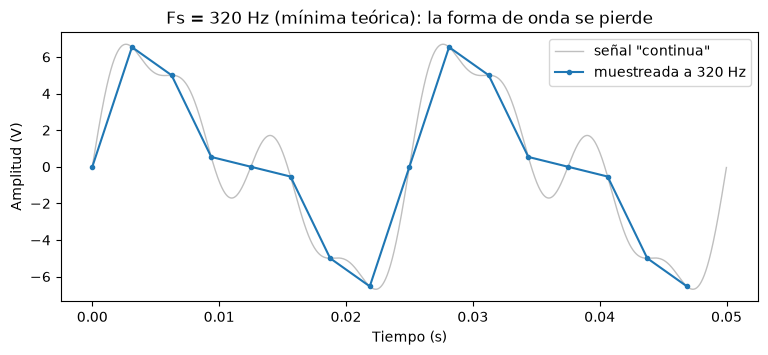

In [7]:
t_320 = np.arange(0, 2*Tp, 1/Fs_min)
x_320 = senal_compuesta(t_320)

plt.figure(figsize=(9, 3.5))
plt.plot(t_ref, x_ref, color='0.75', lw=1, label='señal "continua"')
plt.plot(t_320, x_320, 'o-', ms=3, label=f'muestreada a {Fs_min} Hz')
plt.title('Fs = 320 Hz (mínima teórica): la forma de onda se pierde')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend(loc='upper right')
plt.show()

muestreando exactamente a 320 Hz, la componente de 160 Hz queda con solo 2 muestras por ciclo y, según la fase, puede caer siempre sobre los cruces por cero y desaparecer. Por eso la condición es estricta > y en la práctica se usa entre 5 y 10 veces Fmax.

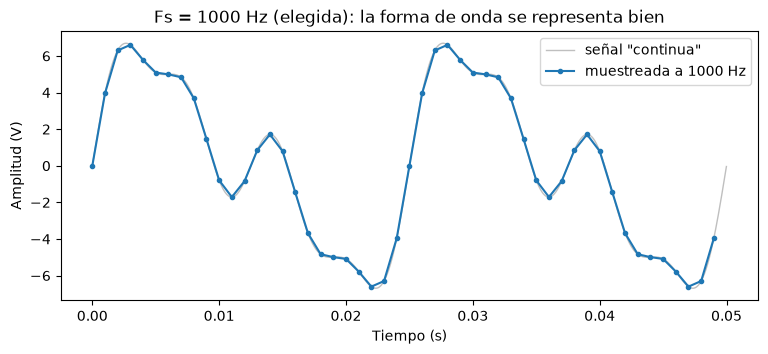

In [8]:
Fs_sel = 1000
t_1000 = np.arange(0, 2*Tp, 1/Fs_sel)
x_1000 = senal_compuesta(t_1000)

plt.figure(figsize=(9, 3.5))
plt.plot(t_ref, x_ref, color='0.75', lw=1, label='señal "continua"')
plt.plot(t_1000, x_1000, 'o-', ms=3, label=f'muestreada a {Fs_sel} Hz')
plt.title('Fs = 1000 Hz (elegida): la forma de onda se representa bien')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend(loc='upper right')
plt.show()

Fs = 1000 Hz | duración = 0.25 s | N = 250 muestras


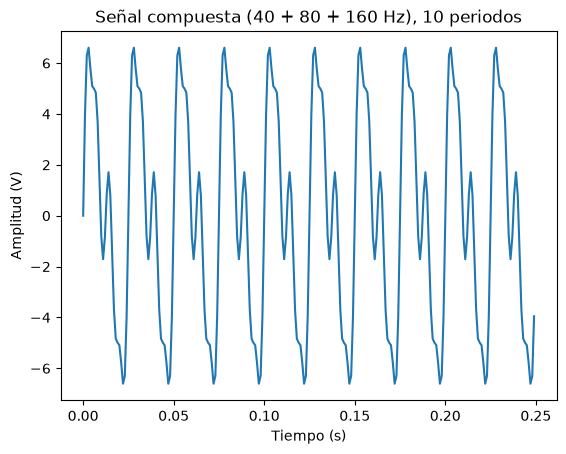

In [ ]:
# Señal definitiva: Fs = 1000 Hz y 10 periodos de la señal
Fs = 1000
T = 1/Fs
t = np.arange(0, 10*Tp, T)      # 250 muestras (10 periodos completos)
x = senal_compuesta(t)
N = len(x)
print('Fs =', Fs, 'Hz | duración =', 10*Tp, 's | N =', N, 'muestras')

plt.plot(t, x)
plt.title('Señal compuesta (40 + 80 + 160 Hz), en 10 periodos')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud (V)')
plt.show()

# punto 2
Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal). (10%)

In [ ]:
X = np.fft.fft(x)
F = np.arange(0, N)*Fs/N                 

Nmitad = int(np.ceil(N/2))
Fmitad = F[:Nmitad]
Xmitad = X[:Nmitad]
amp = 2*np.abs(Xmitad)/N               

In [15]:
picos, _ = signal.find_peaks(amp, height=0.5)
for k in picos:
    print(f'k = {k:3d} -> F = {Fmitad[k]:6.1f} Hz | |X(k)| = {np.abs(Xmitad[k]):6.1f} | amplitud = {amp[k]:.2f} V')

k =  10 -> F =   40.0 Hz | |X(k)| =  625.0 | amplitud = 5.00 V
k =  20 -> F =   80.0 Hz | |X(k)| =  375.0 | amplitud = 3.00 V
k =  40 -> F =  160.0 Hz | |X(k)| =  187.5 | amplitud = 1.50 V


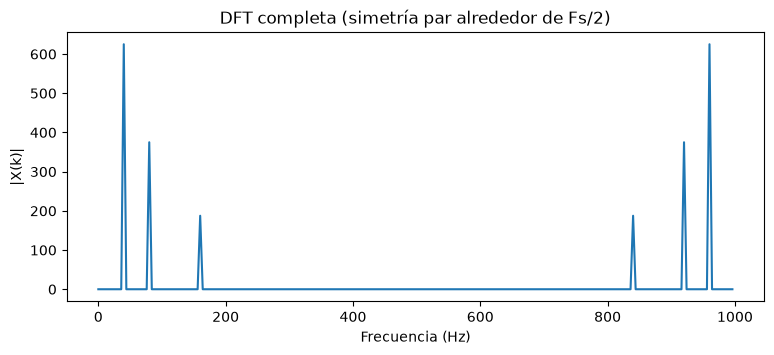

In [ ]:
plt.figure(figsize=(9, 3.5))
plt.plot(F, np.abs(X))
plt.title('DFT completa (simetría par alrededor de Fs/2)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('X(k)')
plt.show()

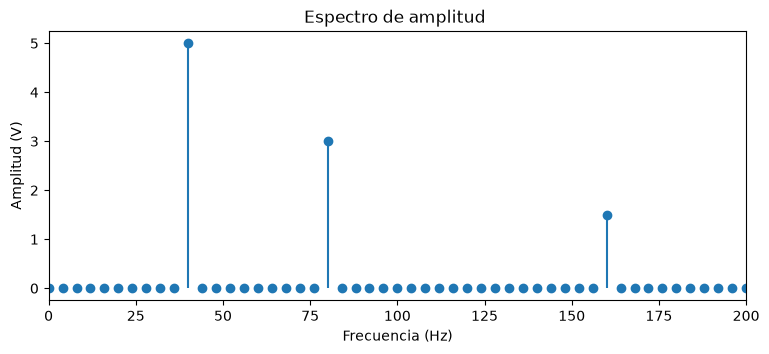

In [16]:
plt.figure(figsize=(9, 3.5))
plt.stem(Fmitad, amp, basefmt=' ')
plt.xlim(0, 200)
plt.title('Espectro de amplitud ')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud (V)')
plt.show()

El espectro muestra tres picos en 40, 80 y 160 Hz que son justo las tres ondas con las que se construyó la señal. La altura de cada pico corresponde a su amplitud (5, 3 y 1,5 V).
Fuera de esos tres picos el espectro vale cero, porque cada frecuencia cae exactamente en una de las "casillas" de la FFT (cada 4 Hz), y así no hay fuga espectral. La mitad derecha de la DFT completa es un espejo de la izquierda porque la señal es real; por eso basta con graficar de 0 a $F_s/2$.

# punto 3 

Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior. (10%)

La función es numpy.fft.ifft (también existe otra llamada scipy.fft.ifft), el calculo que realiza es 

$$x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{\,j 2\pi k n / N}, \qquad n = 0,\dots,N-1$$

Recibe el vector complejo de la DFT y devuelve un vector complejo; para una señal real la parte imaginaria es solo error numérico (≈ 1e-15), así que se toma np.real. Para señales reales también existe el par np.fft.rfft / np.fft.irfft, que trabaja solo con la mitad positiva del espectro.

Máx - parte imaginaria : 1.7311975498406352e-15
Máx error de reconstrucción: 3.552713678800501e-15


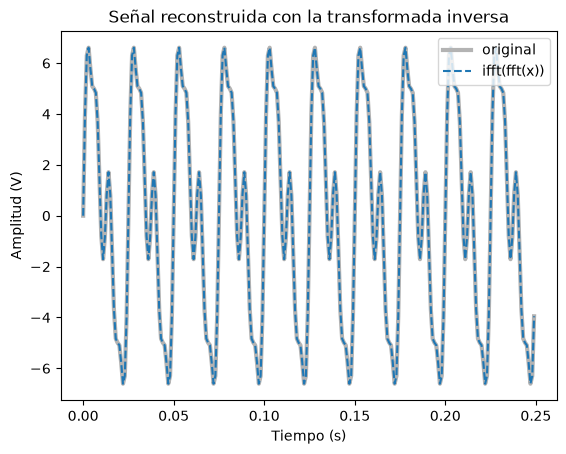

In [18]:
x_rec = np.fft.ifft(X)

print('Máx - parte imaginaria :', np.max(np.abs(np.imag(x_rec))))
print('Máx error de reconstrucción:', np.max(np.abs(np.real(x_rec) - x)))

plt.plot(t, x, lw=3, color='0.7', label='original')
plt.plot(t, np.real(x_rec), '--', label='ifft(fft(x))')
plt.title('Señal reconstruida con la transformada inversa')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud (V)')
plt.legend(); plt.show()

La señal reconstruida coincide con la original (error del orden de 10^-15). La DFT es una transformación invertible: no se pierde información al pasar al dominio de la frecuencia y volver.

# punto 4 
¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? Extraiga de manera similar cada una de las componentes de la señal.

```python
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)))
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)
```

Bins conservados: [9, 10, 11, 12] -> ['36 Hz', '40 Hz', '44 Hz', '48 Hz']
Amplitud máx. de la parte real : 2.495 V
Amplitud máx. de la parte imag.: 2.48 V


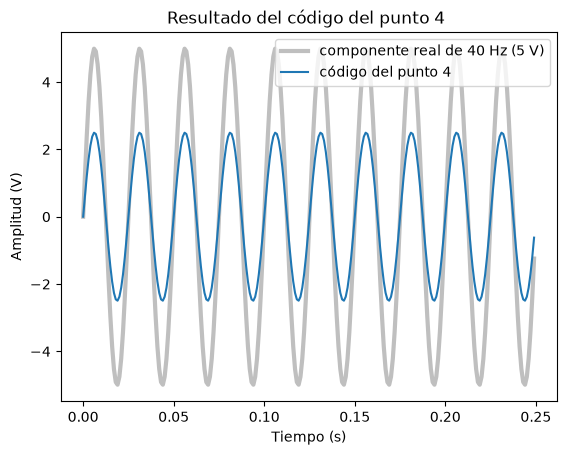

In [22]:
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)), dtype=complex)   # dtype complejo: si no, numpy va a descarta la parte imaginaria
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)

print('Bins conservados:', list(range(9, 13)), '->', [f'{k*Fs/N:.0f} Hz' for k in range(9, 13)])
print('Amplitud máx. de la parte real :', np.max(np.real(xr)).round(3), 'V')
print('Amplitud máx. de la parte imag.:', np.max(np.imag(xr)).round(3), 'V')

fig, ax = plt.subplots()
ax.plot(t, A1*np.sin(2*np.pi*f1*t), lw=3, color='0.75', label='componente real de 40 Hz (5 V)')
ax.plot(t, np.real(xr), label='código del punto 4 ')
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)', title='Resultado del código del punto 4 ')
ax.legend(loc='upper right'); plt.show()

Sí, es un filtro. Un filtro deja pasar algunas frecuencias y elimina otras, y eso es lo que hace el codigo de este punto

fft  pasa la señal al espectro de frecuencia. Se crea un espectro vacío  y solo se copian las casillas 9 a 12.
Como cada casilla mide F_s/N = 1000/250 = 4 Hz, esas casillas son 36, 40, 44 y 48 Hz. Solo queda la onda de 40 Hz las de 80 y 160 Hz se borran.
Por ultimo ifft regresa al dominio del tiempo y entrega la señal filtrada.

el espectro de una señal real tiene dos mitades en espejo, y cada una lleva la mitad de la onda. El código solo copia la mitad izquierda, por eso la onda filtrada sale con la mitad de la amplitud (2,5 V en vez de 5 V) y con una parte imaginaria que no debería tener.

 40 Hz: amplitud = 4.990 V | error vs teórica = 3.0e-14 | máx. imag = 1.0e-15
 80 Hz: amplitud = 2.994 V | error vs teórica = 3.2e-14 | máx. imag = 8.3e-16
160 Hz: amplitud = 1.497 V | error vs teórica = 3.8e-14 | máx. imag = 2.3e-16


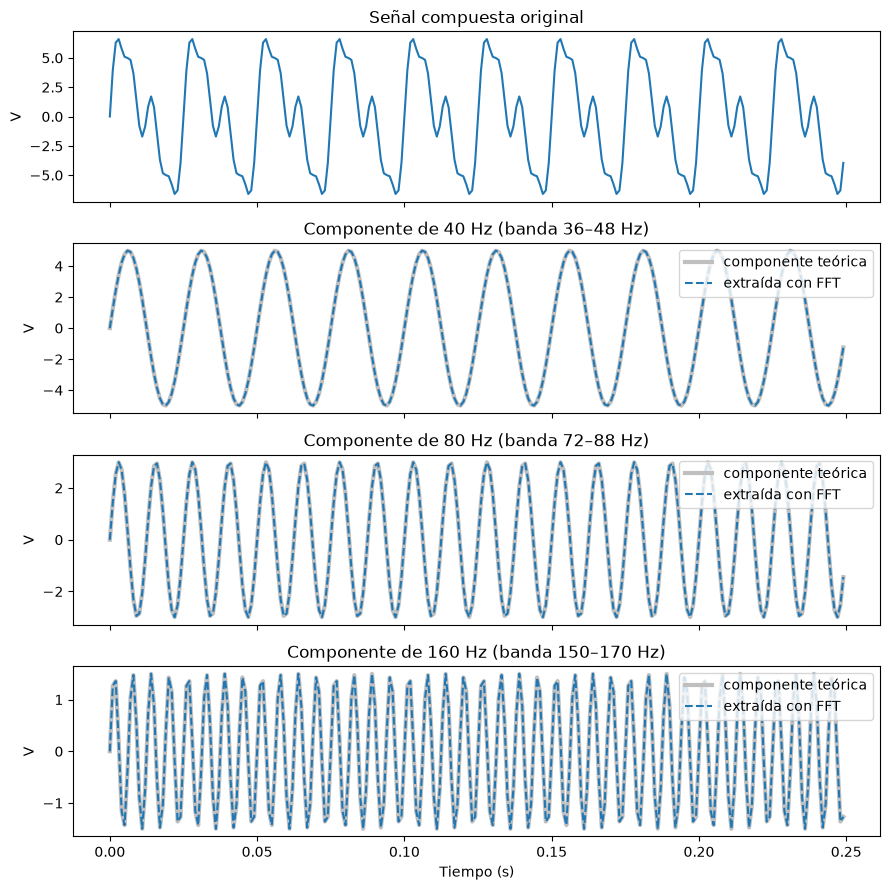

Error de la suma de las 3 componentes vs la señal original: 9.44802342684553e-14


In [24]:
def filtro_fft(x, Fs, f_low, f_high):
    '''Filtro ideal en frecuencia: conserva solo las frecuencias en [f_low, f_high] Hz,
    tanto en la mitad positiva como en su simétrica negativa, para que la salida sea real.'''
    N = len(x)
    X = np.fft.fft(x)
    f = np.fft.fftfreq(N, d=1/Fs)              # frecuencias con signo: 0, +, ..., -, ...
    H = (np.abs(f) >= f_low) & (np.abs(f) <= f_high)
    xf = np.fft.ifft(X*H)
    return np.real(xf), np.max(np.abs(np.imag(xf)))

bandas = {'40 Hz': (36, 48, A1, f1), '80 Hz': (72, 88, A2, f2), '160 Hz': (150, 170, A3, f3)}

fig, axs = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
axs[0].plot(t, x); axs[0].set_title('Señal compuesta original'); axs[0].set_ylabel('V')
suma = np.zeros_like(x)
for ax, (nombre, (fl, fh, Ai, fi)) in zip(axs[1:], bandas.items()):
    comp, imag_max = filtro_fft(x, Fs, fl, fh)
    suma += comp
    ideal = Ai*np.sin(2*np.pi*fi*t)
    ax.plot(t, ideal, lw=3, color='0.75', label='componente teórica')
    ax.plot(t, comp, '--', label='extraída con FFT')
    ax.set_title(f'Componente de {nombre} (banda {fl}–{fh} Hz)'); ax.set_ylabel('V')
    ax.legend(loc='upper right')
    print(f'{nombre:>6}: amplitud = {comp.max():.3f} V | error vs teórica = {np.max(np.abs(comp-ideal)):.1e} | máx. imag = {imag_max:.1e}')
axs[-1].set_xlabel('Tiempo (s)')
plt.tight_layout(); plt.show()

print('Error de la suma de las 3 componentes vs la señal original:', np.max(np.abs(suma - x)))

Con la máscara simétrica, cada componente se recupera con su amplitud correcta (5, 3 y 1,5 V), la parte imaginaria es ≈ 0 y la suma de las tres componentes reconstruye la señal original. Hay que tener en cuenta que en este ejemplo el filtro funciona perfecto porque cada sinusoide cae exactamente en un bin; en una señal real (como el ECG), un filtro ideal en frecuencia con bordes abruptos produce oscilaciones (fenómeno de Gibbs) en el tiempo.
